In [2]:
from data.clevr import CLEVRStream, clevr_collate

In [3]:
from torch.utils.data import DataLoader
train_ds = CLEVRStream("data/clevr_with_masks_train.tfrecords", image_size=(128, 128), max_objects=6)
train_loader = DataLoader(train_ds, batch_size=64, collate_fn=clevr_collate, num_workers=4)


In [4]:
batch = next(iter(train_loader))

for k, v in batch.items():
    if hasattr(v, "shape"):
        print(f"{k:18s} shape={tuple(v.shape)}  dtype={v.dtype}")
    else:
        print(f"{k:18s} type={type(v)}  example={v[0] if len(v) else v}")

print("image min/max:", batch["image"].min().item(), batch["image"].max().item())
print("label_map unique values (first sample):", batch["label_map"][0].unique())
print("num_true_objects (first 8 samples):", batch["num_true_objects"][:8] if hasattr(batch["num_true_objects"], "__getitem__") else batch["num_true_objects"])

image              shape=(64, 3, 128, 128)  dtype=torch.float32
label_map          shape=(64, 128, 128)  dtype=torch.int64
visibility         shape=(64, 11)  dtype=torch.float32
num_true_objects   shape=(64,)  dtype=torch.int64
labels             type=<class 'list'>  example=['green metal cylinder', 'purple rubber cube', 'yellow rubber cylinder', 'gray metal cylinder', 'purple metal cylinder']
image min/max: 0.003921568859368563 1.0
label_map unique values (first sample): tensor([0, 1, 2, 3, 4, 5])
num_true_objects (first 8 samples): tensor([5, 6, 3, 4, 5, 5, 5, 5])


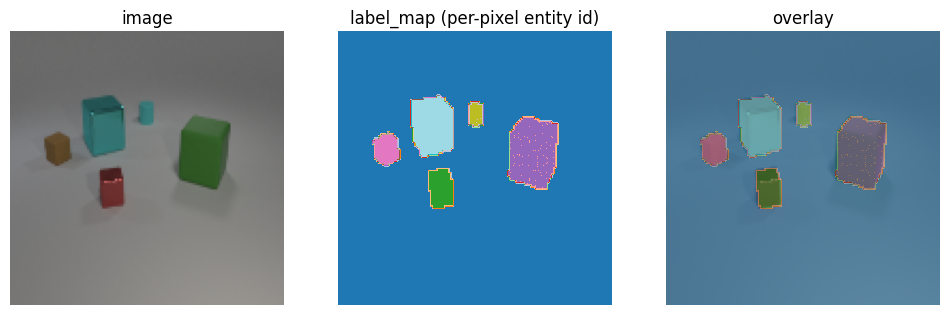

num_true_objects: 5
entity id -> object label  (entity id matches the colors in label_map above)
0 -> background
1 -> red metal cube
2 -> green rubber cube
3 -> brown rubber cube
4 -> cyan rubber cylinder
5 -> cyan metal cube


In [5]:
import matplotlib.pyplot as plt

idx = 10  # which sample in the batch to look at
image = batch["image"][idx].permute(1, 2, 0).numpy()          # [H, W, 3]
label_map = batch["label_map"][idx].numpy()                     # [H, W]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set_title("image")
axes[1].imshow(label_map, cmap="tab20")
axes[1].set_title("label_map (per-pixel entity id)")
axes[2].imshow(image)
axes[2].imshow(label_map, cmap="tab20", alpha=0.5)
axes[2].set_title("overlay")
for ax in axes:
    ax.axis("off")
plt.show()

# --- per-object labels, matched to their entity id in label_map ---
visibility = batch["visibility"][idx]  # [11], index 0 = background, 1..10 = objects
print(f"num_true_objects: {batch['num_true_objects'][idx].item()}")
print("entity id -> object label  (entity id matches the colors in label_map above)")
print("0 -> background")

# batch["labels"][idx] was built by clevr_collate walking entity ids 1..10 in
# order and appending only visible ones — so zipping visible entity ids with
# that list in the same order recovers the entity_id <-> label pairing
visible_entity_ids = [e for e in range(1, 11) if visibility[e] == 1]
for entity_id, label in zip(visible_entity_ids, batch["labels"][idx]):
    print(f"{entity_id} -> {label}")

In [ ]:
print(type(batch["color"]), len(batch["color"]))
print(type(batch["color"][0]), batch["color"][0])

<class 'list'> 64
<class 'list'> [np.str_(''), np.str_('\x06'), np.str_('\x08'), np.str_('\x05'), np.str_('\x01'), np.str_(''), np.str_(''), np.str_(''), np.str_(''), np.str_(''), np.str_('')]


In [1]:
import torch
from torch.utils.data import DataLoader

from Config import Config
from data.clevr import CLEVRDataset, clevr_collate

cfg = Config()
ds = CLEVRDataset(cfg.train_dir, image_size=cfg.image_size, max_objects=cfg.max_objects)
loader = DataLoader(ds, batch_size=32, shuffle=True, collate_fn=clevr_collate)

all_bg_pixels = []
for i, batch in enumerate(loader):
    if i >= 20:   # ~640 images is plenty to get a reliable range
        break
    image = batch["image"]          # [B, 3, H, W]
    label_map = batch["label_map"]  # [B, H, W], 0 = background

    bg_mask = (label_map == 0).unsqueeze(1)          # [B, 1, H, W]
    bg_mask = bg_mask.expand(-1, 3, -1, -1)           # [B, 3, H, W]
    all_bg_pixels.append(image[bg_mask])              # flat tensor of just background pixel values

bg_pixels = torch.cat(all_bg_pixels)
print(f"n background pixels sampled: {bg_pixels.numel():,}")
print(f"min:  {bg_pixels.min().item():.4f}")
print(f"max:  {bg_pixels.max().item():.4f}")
print(f"mean: {bg_pixels.mean().item():.4f}")
print(f"1st percentile:  {bg_pixels.quantile(0.01).item():.4f}")
print(f"99th percentile: {bg_pixels.quantile(0.99).item():.4f}")

n background pixels sampled: 28,599,201
min:  0.0154
max:  1.0000
mean: 0.4853


RuntimeError: quantile() input tensor is too large

In [1]:
import torch
import time

from Config import Config
from SlotModel import build_model
from data.clevr import CLEVRDataset, clevr_collate
from torch.utils.data import DataLoader
import torch.nn.functional as F

def find_batch_size(candidates=(2, 4, 8, 16, 32, 64), warmup_steps=3, timed_steps=10):
    cfg = Config()
    device = "cuda"

    for bs in candidates:
        try:
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

            model = build_model(cfg, device)
            optimizer = torch.optim.Adam(model.parameters(), lr=cfg.base_lr)
            ds = CLEVRDataset(cfg.train_dir, image_size=cfg.image_size, max_objects=cfg.max_objects)
            loader = DataLoader(ds, batch_size=bs, shuffle=True, collate_fn=clevr_collate)
            it = iter(loader)

            # warmup -- first few steps include cudnn autotuning/allocation overhead,
            # don't count them toward the timed measurement
            for _ in range(warmup_steps):
                batch = {k: v.to(device) if torch.is_tensor(v) else v for k, v in next(it).items()}
                recon, masks, _ = model(batch)
                loss = F.mse_loss(recon, batch["image"])
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            torch.cuda.synchronize()
            start = time.time()
            for _ in range(timed_steps):
                batch = {k: v.to(device) if torch.is_tensor(v) else v for k, v in next(it).items()}
                recon, masks, _ = model(batch)
                loss = F.mse_loss(recon, batch["image"])
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            torch.cuda.synchronize()
            elapsed = time.time() - start

            steps_per_sec = timed_steps / elapsed
            imgs_per_sec = steps_per_sec * bs
            peak_mem_gb = torch.cuda.max_memory_allocated() / 1e9

            print(f"batch_size={bs:4d} | {steps_per_sec:6.2f} it/s | {imgs_per_sec:7.1f} img/s | peak mem {peak_mem_gb:.2f} GB")

            del model, optimizer, loader, it
            torch.cuda.empty_cache()

        except torch.cuda.OutOfMemoryError:
            print(f"batch_size={bs:4d} | OUT OF MEMORY -- stopping sweep")
            torch.cuda.empty_cache()
            break

if __name__ == "__main__":
    find_batch_size()

c:\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W0910 10:59:03.669000 20536 torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W0910 10:59:03.731000 20536 torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 62493.75it/s]


build_model: image_encoder=vit, text_encoder=CLIP(openai/clip-vit-base-patch32)
total:     152,145,349
trainable: 868,036
frozen:    151,277,313
batch_size=   2 |  16.79 it/s |    33.6 img/s | peak mem 0.98 GB


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 56745.29it/s]


build_model: image_encoder=vit, text_encoder=CLIP(openai/clip-vit-base-patch32)
total:     152,145,349
trainable: 868,036
frozen:    151,277,313
batch_size=   4 |  10.45 it/s |    41.8 img/s | peak mem 1.30 GB


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 44218.40it/s]


build_model: image_encoder=vit, text_encoder=CLIP(openai/clip-vit-base-patch32)
total:     152,145,349
trainable: 868,036
frozen:    151,277,313
batch_size=   8 |   5.66 it/s |    45.3 img/s | peak mem 1.95 GB


... (2 outputs left out)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 49761.02it/s]


build_model: image_encoder=vit, text_encoder=CLIP(openai/clip-vit-base-patch32)
total:     152,145,349
trainable: 868,036
frozen:    151,277,313
batch_size=  32 |   1.20 it/s |    38.5 img/s | peak mem 5.81 GB


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 36138.22it/s]


build_model: image_encoder=vit, text_encoder=CLIP(openai/clip-vit-base-patch32)
total:     152,145,349
trainable: 868,036
frozen:    151,277,313
batch_size=  64 |   0.04 it/s |     2.6 img/s | peak mem 10.96 GB
